In [52]:
import pandas as pd


In [53]:
train = pd.read_csv("train.csv")

In [54]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Index           20000 non-null  int64  
 1   Height(Inches)  20000 non-null  float64
 2   Weight(Pounds)  20000 non-null  float64
dtypes: float64(2), int64(1)
memory usage: 468.9 KB


In [55]:
train.describe(include="all")

,Index,Height(Inches),Weight(Pounds)
count,20000.000000,20000.000000,20000.000000
mean,12508.934500,67.990345,127.078146
std,7212.107436,1.897143,11.632654
min,1.000000,60.278360,78.567850
25%,6265.750000,66.703840,119.264175
50%,12517.500000,67.993805,127.138400
75%,18745.250000,69.270813,134.873825
max,24999.000000,75.152800,170.924000


In [56]:
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [57]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [58]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [59]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
kategorical_features = train[less].select_dtypes(include=['object','string']).columns

for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

In [60]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

In [61]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

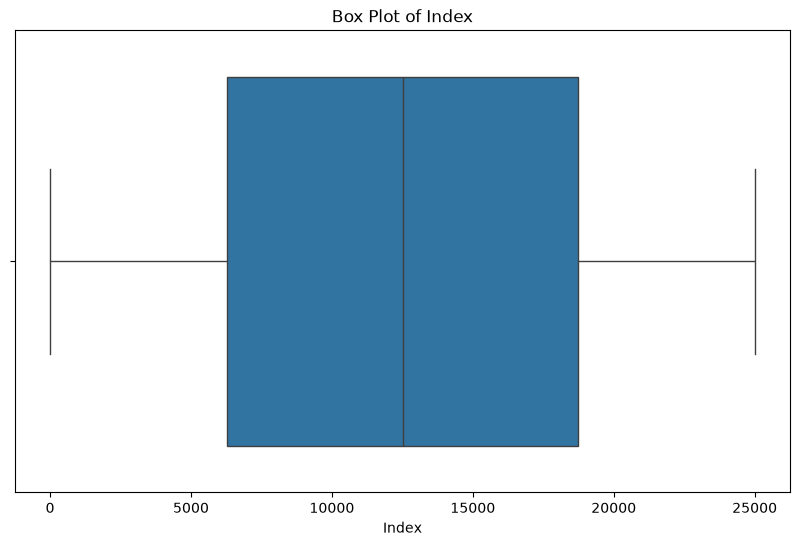

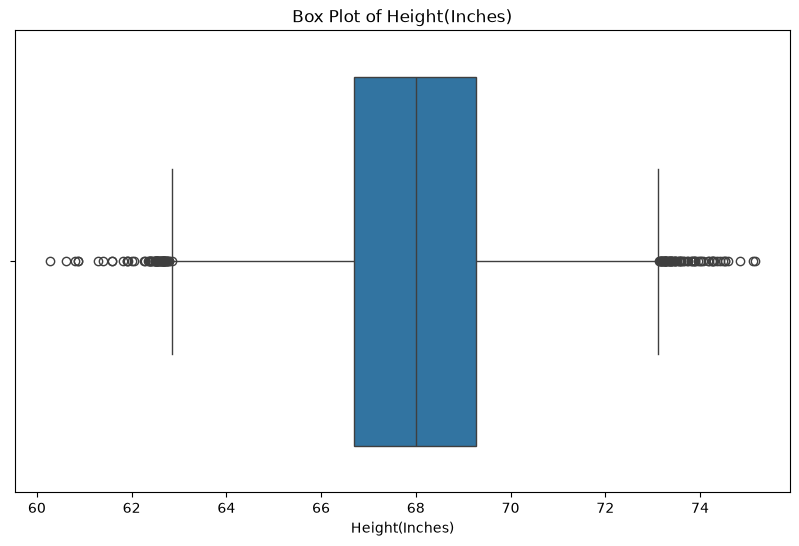

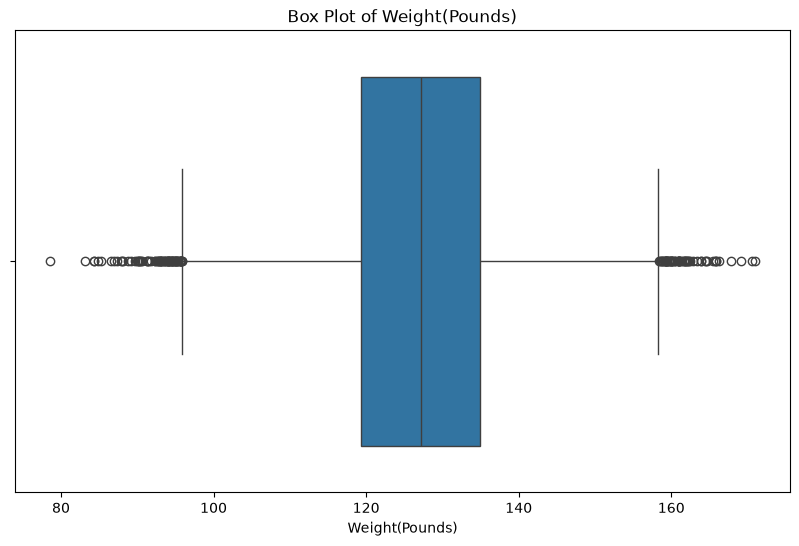

In [62]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [63]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [64]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung outliers pada kolom numerik
condition = ~((df[numeric_features] < (Q1 - 1.5 *IQR)) | (df[numeric_features] > (Q3 + 1.5* IQR))).any(axis=1)
df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object','string']).columns
df = pd.concat([df_filtered_numeric, df.loc[condition, categorical_features]], axis=1)

In [65]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

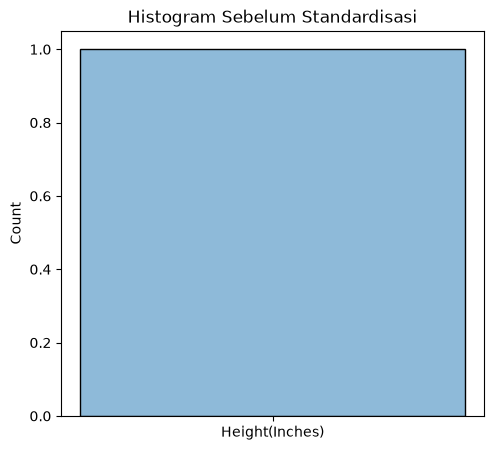

In [66]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot([numeric_features[1]], kde=True)
plt.title("Histogram Sebelum Standardisasi")
plt.show()

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

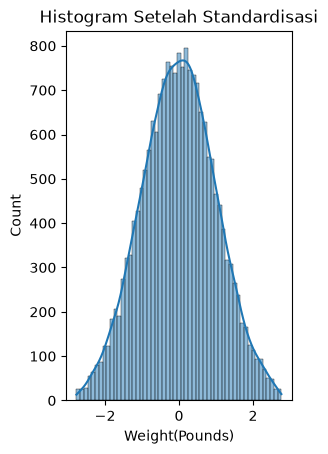

In [67]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[2]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [68]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [Index, Height(Inches), Weight(Pounds)]
Index: []


In [69]:
# Menghapus baris duplikat
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
          Index  Height(Inches)  Weight(Pounds)
0      1.497697       -0.023480       -1.459917
1      1.540959       -0.783156       -0.008276
2     -1.593228        1.122352        1.166997
3      0.018723        0.266194        0.529831
4     -1.522095       -1.024249       -1.035534
...         ...             ...             ...
19995  1.256979       -0.274215       -1.384403
19996 -0.987273       -0.581209       -0.325032
19997 -1.615414        0.218691       -0.543876
19998  0.455510        0.711010        0.759652
19999  1.545258       -0.470736       -0.383738

[19735 rows x 3 columns]


In [70]:
category_features = df.select_dtypes(include=['object','string']).columns
df[category_features]

""
0
1
2
3
4
...
19995
19996
19997
19998


In [71]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,Index,Height(Inches),Weight(Pounds)
0,1.497697,-0.023480,-1.459917
1,1.540959,-0.783156,-0.008276
2,-1.593228,1.122352,1.166997
3,0.018723,0.266194,0.529831
4,-1.522095,-1.024249,-1.035534
...,...,...,...
19995,1.256979,-0.274215,-1.384403
19996,-0.987273,-0.581209,-0.325032
19997,-1.615414,0.218691,-0.543876
19998,0.455510,0.711010,0.759652


In [72]:
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

# Menampilkan hasil
df_lencoder

,Index,Height(Inches),Weight(Pounds)
0,1.497697,-0.023480,-1.459917
1,1.540959,-0.783156,-0.008276
2,-1.593228,1.122352,1.166997
3,0.018723,0.266194,0.529831
4,-1.522095,-1.024249,-1.035534
...,...,...,...
19995,1.256979,-0.274215,-1.384403
19996,-0.987273,-0.581209,-0.325032
19997,-1.615414,0.218691,-0.543876
19998,0.455510,0.711010,0.759652


In [73]:
df_lencoder.head()

,Index,Height(Inches),Weight(Pounds)
0,1.497697,-0.023480,-1.459917
1,1.540959,-0.783156,-0.008276
2,-1.593228,1.122352,1.166997
3,0.018723,0.266194,0.529831
4,-1.522095,-1.024249,-1.035534


In [74]:
# Menghitung jumlah dan persentase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100
 
missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)
 
missing_data[missing_data['Missing Values'] > 0] # Menampilkan kolom dengan missing values

,Missing Values,Percentage


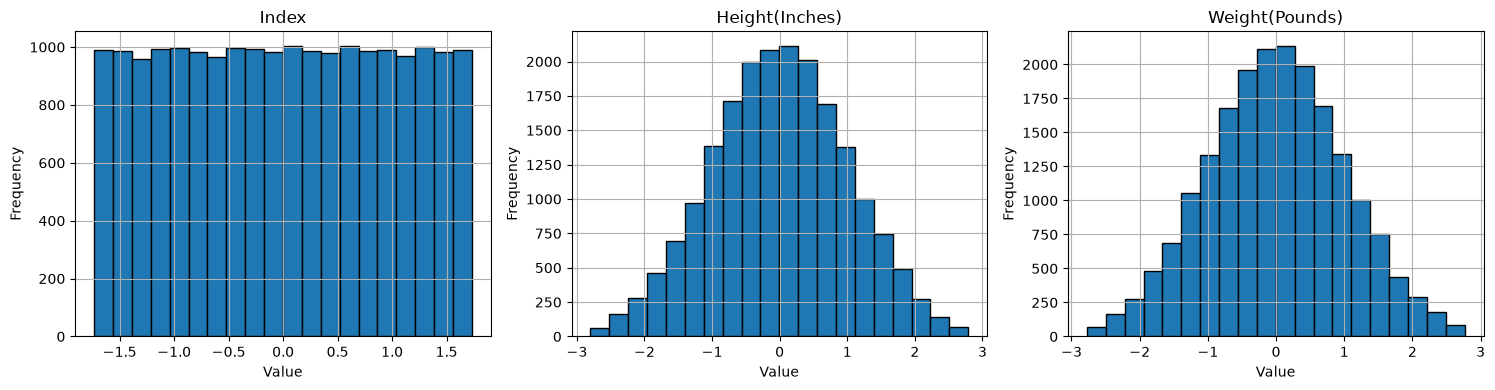

In [75]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4 # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols) # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()


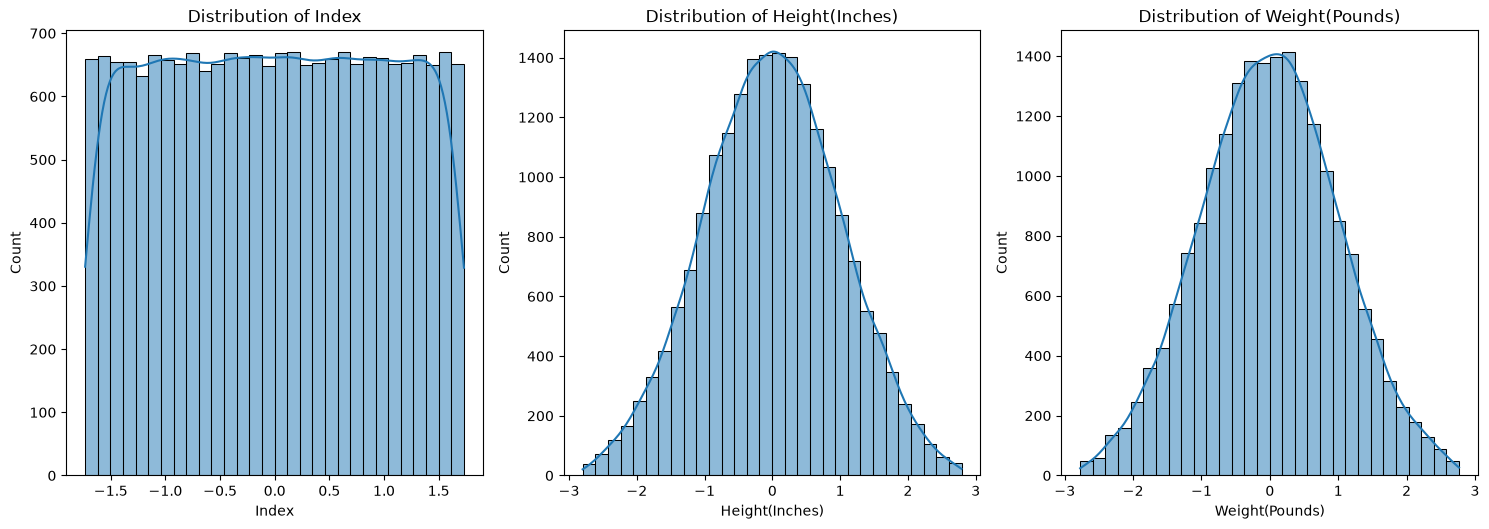

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = ['Index', 'Height(Inches)', 'Weight(Pounds)']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

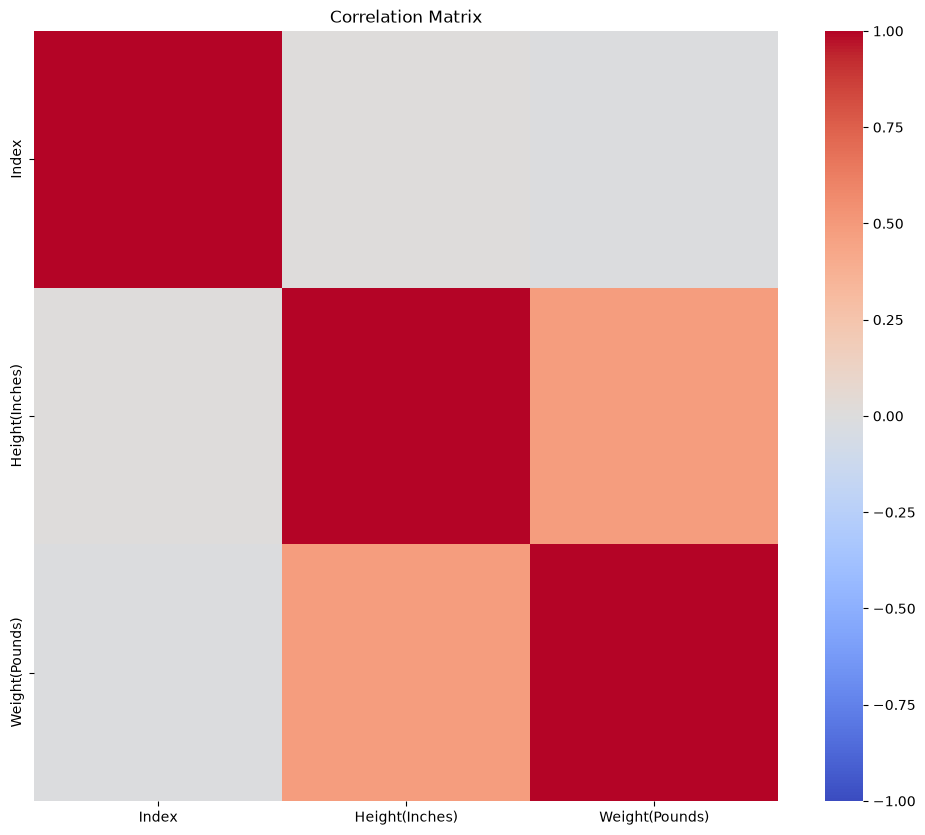

In [77]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

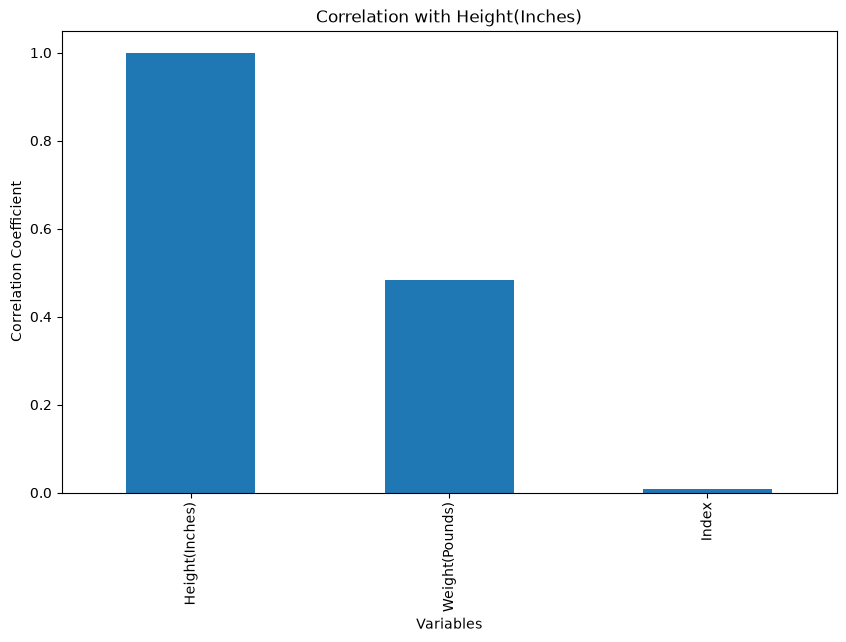

In [78]:
# Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['Height(Inches)']

# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with Height(Inches)')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

In [79]:
import sklearn

In [80]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=['Height(Inches)'])
y = df_lencoder['Height(Inches)']

In [81]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)


In [82]:
# menghitung panjang/jumlah data 
print("Jumlah data: ",len(X))
# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ",len(x_test))

Jumlah data:  19735
Jumlah data latih:  15788
Jumlah data test:  3947


In [83]:
# Menghitung jumlah data kosong pada setiap kolom
import numpy as np

print("Jumlah NaN pada X_train:",
np.isnan(x_train).sum())
print("Jumlah NaN pada y_train:",
np.isnan(y_train).sum())

Jumlah NaN pada X_train: Index             0
Weight(Pounds)    0
dtype: int64
Jumlah NaN pada y_train: 0


In [84]:
from sklearn.impute import SimpleImputer

#Mengisi nilai kosong berdasarkan median data pelatihan
imputer = SimpleImputer(strategy="median")

x_train = imputer.fit_transform(x_train)
x_test = imputer.transform(x_test)

# Memastikan tidak ada NaN pada data fitur
import numpy as np

print("NaN pada X_train:", np.isnan(x_train).sum())
print("NaN pada X_test:", np.isnan(x_test).sum())

NaN pada X_train: 0
NaN pada X_test: 0


In [85]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(x_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",184
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, in

In [86]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
'MAE': [mae_lars],
'MSE': [mse_lars],
'R2': [r2_lars]
}

# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results



,MAE,MSE,R2
Lars,0.701759,0.763166,0.243577


In [87]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results

,MAE,MSE,R2
Lars,0.701759,0.763166,0.243577
Linear Regression,0.701334,0.762474,0.244262


In [88]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.701759,0.763166,0.243577
Linear Regression,0.701334,0.762474,0.244262
GradientBoostingRegressor,0.703212,0.765972,0.240796


In [89]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model.joblib')

['gbr_model.joblib']

In [90]:
import pickle

# Menyimpan model ke dalam file
with open('gbr_model.pkl', 'wb') as file:
    pickle.dump(GBR, file)


In [91]:
# Memuat model dari file joblib
joblib_model = joblib.load('gbr_model.joblib')

# Memuat model dari file pickle
with open('gbr_model.pkl', 'rb') as file:
    pickle_model = pickle.load(file)


In [92]:
from flask import Flask, request, jsonify
import joblib

# Inisialisasi aplikasi Flask
app = Flask(__name__)

# Memuat model yang telah disimpan
joblib_model = joblib.load('gbr_model.joblib') # Pastikan path file sesuai dengan penyimpanan Anda

@app.route('/predict', methods=['POST'])
def predict():
    data = request.json['data'] # Mengambil data dari request JSON
    prediction = joblib_model.predict(data) # Melakukan prediksi (harus dalam bentuk 2D array)
    return jsonify({'prediction': prediction.tolist()})

if __name__ == '__main__':
    app.run(debug=False, use_reloader=False)

 * Serving Flask app '__main__'


 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit


In [ ]:
{
   "data": [[ 2.58814198e-02, -9.17637181e-01, 7.98581973e-01,
   4.65818252e-03, -1.90862680e-01, -5.23676539e-01,
   5.44502437e-01, 3.98055532e-01, -7.01765886e-01,
   1.84842886e+00, 0.00000000e+00, -7.99528238e-01,
   1.40061034e+00, 1.30453595e+00, -7.43485947e-01,
   0.00000000e+00, 1.75076143e-01, 1.15778146e+00,
   0.00000000e+00, 7.87362373e-01, -7.89877652e-01,
   2.94736730e-01, 0.00000000e+00, -2.35844028e-01,
  -9.44263321e-01, 4.99353260e-01, 2.73711363e-01,
   5.33168369e-01, 7.90365547e-01, -3.15583095e-01,
   0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
   0.00000000e+00, 0.00000000e+00, 2.51894504e-01,
  -1.35256152e+00, 2.00000000e+00, 1.00000000e+00,
   0.00000000e+00, 3.00000000e+00, 0.00000000e+00,
   4.00000000e+00, 0.00000000e+00, 3.00000000e+00,
   2.00000000e+00, 0.00000000e+00, 0.00000000e+00,
   2.00000000e+00, 0.00000000e+00, 0.00000000e+00,
   7.00000000e+00, 9.00000000e+00, 1.00000000e+00,
   3.00000000e+00, 1.00000000e+00, 2.00000000e+00,
   2.00000000e+00, 2.00000000e+00, 1.00000000e+00,
   2.00000000e+00, 0.00000000e+00, 0.00000000e+00,
   0.00000000e+00, 1.00000000e+00, 2.00000000e+00,
   2.00000000e+00, 4.00000000e+00, 2.00000000e+00,
   0.00000000e+00, 1.00000000e+00, 2.00000000e+00,
   3.00000000e+00, 2.00000000e+00, 8.00000000e+00,
   3.00000000e+00]]
}


{'data': [[0.0258814198,
   -0.917637181,
   0.798581973,
   0.00465818252,
   -0.19086268,
   -0.523676539,
   0.544502437,
   0.398055532,
   -0.701765886,
   1.84842886,
   0.0,
   -0.799528238,
   1.40061034,
   1.30453595,
   -0.743485947,
   0.0,
   0.175076143,
   1.15778146,
   0.0,
   0.787362373,
   -0.789877652,
   0.29473673,
   0.0,
   -0.235844028,
   -0.944263321,
   0.49935326,
   0.273711363,
   0.533168369,
   0.790365547,
   -0.315583095,
   0.0,
   0.0,
   0.0,
   0.0,
   0.0,
   0.251894504,
   -1.35256152,
   2.0,
   1.0,
   0.0,
   3.0,
   0.0,
   4.0,
   0.0,
   3.0,
   2.0,
   0.0,
   0.0,
   2.0,
   0.0,
   0.0,
   7.0,
   9.0,
   1.0,
   3.0,
   1.0,
   2.0,
   2.0,
   2.0,
   1.0,
   2.0,
   0.0,
   0.0,
   0.0,
   1.0,
   2.0,
   2.0,
   4.0,
   2.0,
   0.0,
   1.0,
   2.0,
   3.0,
   2.0,
   8.0,
   3.0]]}

In [ ]:
print("Bentuk x_train:", x_train.shape)
print("Bentuk y_train:", y_train.shape)

print("\nContoh data fitur:")
print(x_train[:5])

Bentuk x_train: (15788, 2)
Bentuk y_train: (15788,)

Contoh data fitur:
[[ 1.03400945  0.0233838 ]
 [ 0.1307621  -1.7478933 ]
 [-1.58005549 -0.21266797]
 [ 0.72132557  0.21173281]
 [-0.11259054 -1.23330435]]


In [ ]:
print([nama for nama in globals() if nama in ['df', 'data', 'dataset', 'train', 'X', 'y', 'x_train', 'y_train', 'X_train', 'y_train']])

['train', 'df', 'X', 'y', 'x_train', 'y_train', 'data']


In [ ]:
print("Kolom fitur:")
print(X.columns.tolist())

print("\nContoh data fitur:")
print(X.head())

print("\nApakah fitur menggunakan StandardScaler atau MinMaxScaler?")

Kolom fitur:
['Index', 'Weight(Pounds)']

Contoh data fitur:
      Index  Weight(Pounds)
0  1.497697       -1.459917
1  1.540959       -0.008276
2 -1.593228        1.166997
3  0.018723        0.529831
4 -1.522095       -1.035534

Apakah fitur menggunakan StandardScaler atau MinMaxScaler?


In [ ]:
print("Jumlah fitur:", GBR.n_features_in_)
print("Nama fitur:", getattr(GBR, "feature_names_in_", "Nama fitur tidak tersimpan"))

Jumlah fitur: 2
Nama fitur: Nama fitur tidak tersimpan


In [ ]:
print("Rata-rata setelah standardisasi:")
print(df[numeric_features].mean())

print("\nStandar deviasi setelah standardisasi:")
print(df[numeric_features].std())

Rata-rata setelah standardisasi:
Index             6.984813e-17
Height(Inches)    2.983307e-15
Weight(Pounds)   -4.666143e-16
dtype: float64

Standar deviasi setelah standardisasi:
Index             1.000025
Height(Inches)    1.000025
Weight(Pounds)    1.000025
dtype: float64


In [ ]:
# Menyimpan dataset hasil standardisasi
df.to_csv('dataset_standardisasi.csv', index=False)

print("Dataset berhasil disimpan!")

Dataset berhasil disimpan!
